# KAIST VAD — просмотр аудио и Ground Truth

Оригинальный **Recorded Dataset** из [репозитория KAIST VAD](https://github.com/jtkim-kaist/VAD#recorded-dataset): разговорная корейская речь в комнате, парке, на стройке и автобусной остановке. По описанию авторов, Ground Truth размечен вручную.

Здесь используются только WAV и соответствующие MAT из официального архива, без запуска моделей. В проверенных файлах `y_label` содержит одну бинарную метку на каждый аудиосэмпл: `1` — речь, `0` — неречь. Частота всех записей — 16 кГц. Интервалы представлены как `[start, end)` в секундах; соседние речевые сэмплы объединяются без сглаживания.

Запустите ячейки по порядку в существующем `backend/venv`. Нужны NumPy, pandas, Matplotlib, SciPy и IPython. Для другой записи измените `recording_name` в ячейке выбора и повторите последующие ячейки. `preview_start` и `preview_duration` управляют прослушиваемым участком и подробным графиком; таблица речи всегда относится ко всей записи.

In [1]:
from pathlib import Path
import hashlib
import shutil
import sys
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.io import loadmat, wavfile
from IPython.display import Audio, display

print("Python:", sys.executable)

Python: Z:\polikek 7\videoeditor\backend\venv\Scripts\python.exe


## Загрузка оригинального датасета

[Официальная ссылка Download](https://www.dropbox.com/s/jvwepe4hvonona5/record_data.zip?dl=1) из README ведёт на публичный архив Dropbox размером около 206 МБ. Данные сохраняются в `backend/.cache/kaist_vad/`, который уже исключён из Git. Архив и распакованные файлы используются повторно.

SHA-256 ниже зафиксирован после текущего скачивания. Проверка защищает от незаметной замены архива; при несовпадении нужно проверить источник, а не отключать проверку. Если Dropbox начнёт требовать вход, загрузка завершится ошибкой: другие данные автоматически не подставляются.

In [2]:
current_dir = Path.cwd()
backend_dir = next(
    (folder for folder in (current_dir, current_dir / "backend")
     if (folder / "test_venv.ipynb").is_file()),
    None,
)
if backend_dir is None:
    raise FileNotFoundError("Запустите notebook из videoeditor/ или backend/.")

dataset_dir = backend_dir / ".cache" / "kaist_vad"
dataset_dir.mkdir(parents=True, exist_ok=True)
archive_path = dataset_dir / "record_data.zip"
download_url = "https://www.dropbox.com/scl/fi/u53di1wo7529w9n8t6ytc/record_data.zip?rlkey=k8ljo5vga5ttdgbikp552larr&dl=1"
expected_sha256 = "d2e34fd9e00c163c378174a37d9064d42d4065a0ce2ba5b31d263321ba2a4971"

if not archive_path.exists():
    temporary_path = archive_path.with_suffix(".zip.part")
    print("Скачивание официального архива KAIST...")
    with urllib.request.urlopen(download_url, timeout=60) as response:
        with temporary_path.open("wb") as target:
            shutil.copyfileobj(response, target)
    if not zipfile.is_zipfile(temporary_path):
        raise RuntimeError("Вместо ZIP получена другая страница. Проверьте доступ к Dropbox.")
    temporary_path.replace(archive_path)

with archive_path.open("rb") as source:
    archive_sha256 = hashlib.file_digest(source, "sha256").hexdigest()
if archive_sha256 != expected_sha256:
    raise ValueError("SHA-256 архива не совпадает с проверенным источником.")

recording_names = ["room", "park", "construction_site", "bus_stop"]
with zipfile.ZipFile(archive_path) as archive:
    for name in recording_names:
        for suffix in (".wav", ".mat"):
            member = f"record_data/{name}{suffix}"
            destination = dataset_dir / member
            if not destination.exists():
                archive.extract(member, dataset_dir)

data_dir = dataset_dir / "record_data"
print("Датасет:", data_dir)
print("SHA-256:", archive_sha256)

Датасет: Z:\polikek 7\videoeditor\backend\.cache\kaist_vad\record_data
SHA-256: d2e34fd9e00c163c378174a37d9064d42d4065a0ce2ba5b31d263321ba2a4971


In [3]:
recordings = pd.DataFrame([
    {
        "recording": name,
        "wav": f"{name}.wav",
        "ground_truth": f"{name}.mat",
    }
    for name in recording_names
])
display(recordings)

,recording,wav,ground_truth
0,room,room.wav,room.mat
1,park,park.wav,park.mat
2,construction_site,construction_site.wav,construction_site.mat
3,bus_stop,bus_stop.wav,bus_stop.mat


## Выбор записи

Доступны `room`, `park`, `construction_site`, `bus_stop`. По умолчанию загружается комната, а для прослушивания выбран отрезок 280–340 секунд, включающий начало размеченной речи. Можно изменить начало и длительность, в том числе прослушать всю запись.

In [4]:
recording_name = "room"
preview_start = 280.0
preview_duration = 60.0

In [5]:
if recording_name not in recording_names:
    raise ValueError(f"Выберите запись из {recording_names}")

audio_path = data_dir / f"{recording_name}.wav"
label_path = data_dir / f"{recording_name}.mat"
sample_rate, audio = wavfile.read(audio_path, mmap=True)
labels = loadmat(label_path, variable_names=["y_label"])["y_label"].ravel()

if audio.ndim != 1:
    raise ValueError("Ожидалась оригинальная монофоническая запись KAIST.")
if len(labels) != len(audio):
    raise ValueError("Количество меток не совпадает с количеством аудиосэмплов.")
if not np.isin(labels, [0, 1]).all():
    raise ValueError("Ground Truth должен содержать только 0 и 1.")

duration = len(audio) / sample_rate
if np.issubdtype(audio.dtype, np.integer):
    audio_scale = max(abs(int(np.iinfo(audio.dtype).min)), int(np.iinfo(audio.dtype).max))
else:
    audio_scale = 1.0

print("WAV:", audio_path.name)
print("Ground Truth:", label_path.name)
print(f"Частота дискретизации: {sample_rate} Гц")
print(f"Длительность аудио: {duration:.6f} с ({duration / 60:.2f} мин)")
print(f"Аудиосэмплов / эталонных меток: {len(audio)} / {len(labels)}")

WAV:

 room.wav
Ground Truth: room.mat
Частота дискретизации: 16000 Гц
Длительность аудио: 1802.518625 с (30.04 мин)
Аудиосэмплов / эталонных меток: 28840298 / 28840298


## Речевые интервалы всей записи

Начало интервала соответствует первому речевому сэмплу, конец — границе сразу после последнего. Деление индексов на фактическую частоту дискретизации даёт секунды. Полная таблица доступна в переменной `speech_intervals`; длинная таблица в выводе отображается сокращённо.

In [6]:
changes = np.diff(np.pad(labels.astype(np.int8), (1, 1)))
speech_starts = np.flatnonzero(changes == 1)
speech_ends = np.flatnonzero(changes == -1)

speech_intervals = pd.DataFrame({
    "start": speech_starts / sample_rate,
    "end": speech_ends / sample_rate,
})
speech_seconds = (speech_intervals["end"] - speech_intervals["start"]).sum()

print(f"Речевых интервалов: {len(speech_intervals)}")
print(f"Суммарная речь: {speech_seconds:.3f} с ({100 * speech_seconds / duration:.2f}%)")
display(speech_intervals)

Речевых интервалов: 176
Суммарная речь: 548.605 с (30.44%)


,start,end
0,287.347938,287.854
1,288.381937,289.078
2,289.278937,297.582
3,298.759937,301.586
4,302.563938,311.627
...,...,...
171,1773.420938,1786.382
172,1786.640938,1791.345
173,1791.742937,1797.926
174,1798.406937,1798.999


## Прослушивание выбранного участка

Плеер встроен через `IPython.display.Audio`. В notebook сохраняется только выбранный отрезок, чтобы не встраивать все 30 минут аудио. IPython нормализует громкость воспроизведения; исходные WAV и Ground Truth остаются неизменными.

In [7]:
if not np.isfinite([preview_start, preview_duration]).all():
    raise ValueError("Начало и длительность должны быть конечными числами.")
if not 0 <= preview_start < duration or preview_duration <= 0:
    raise ValueError("Начало должно попадать в запись, длительность должна быть положительной.")

first_sample = int(round(preview_start * sample_rate))
last_sample = min(len(audio), int(round((preview_start + preview_duration) * sample_rate)))
if first_sample >= last_sample:
    raise ValueError("Выбранный участок должен содержать хотя бы один аудиосэмпл.")

window_start = first_sample / sample_rate
window_end = last_sample / sample_rate
preview_audio = audio[first_sample:last_sample].astype(np.float32) / audio_scale

print(f"Прослушивание: {window_start:.3f}–{window_end:.3f} с")
display(Audio(data=preview_audio, rate=sample_rate))

Прослушивание: 280.000–340.000 с


## Аудиосигнал и эталонная речь

Верхняя дорожка показывает всю запись, нижняя — выбранный для прослушивания участок. Зелёные области обозначают речь по Ground Truth. Белые промежутки между ними — неречь по разметке, а не гарантированная акустическая тишина. Прореживание применяется только к отрисовке сигнала; интервалы рассчитаны по всем меткам без потери точности.

При выборе `bus_stop` SciPy может предупредить о пропуске служебного WAV-чанка. Аудиосэмплы при этом читаются; соответствие длине Ground Truth проверяется выше.

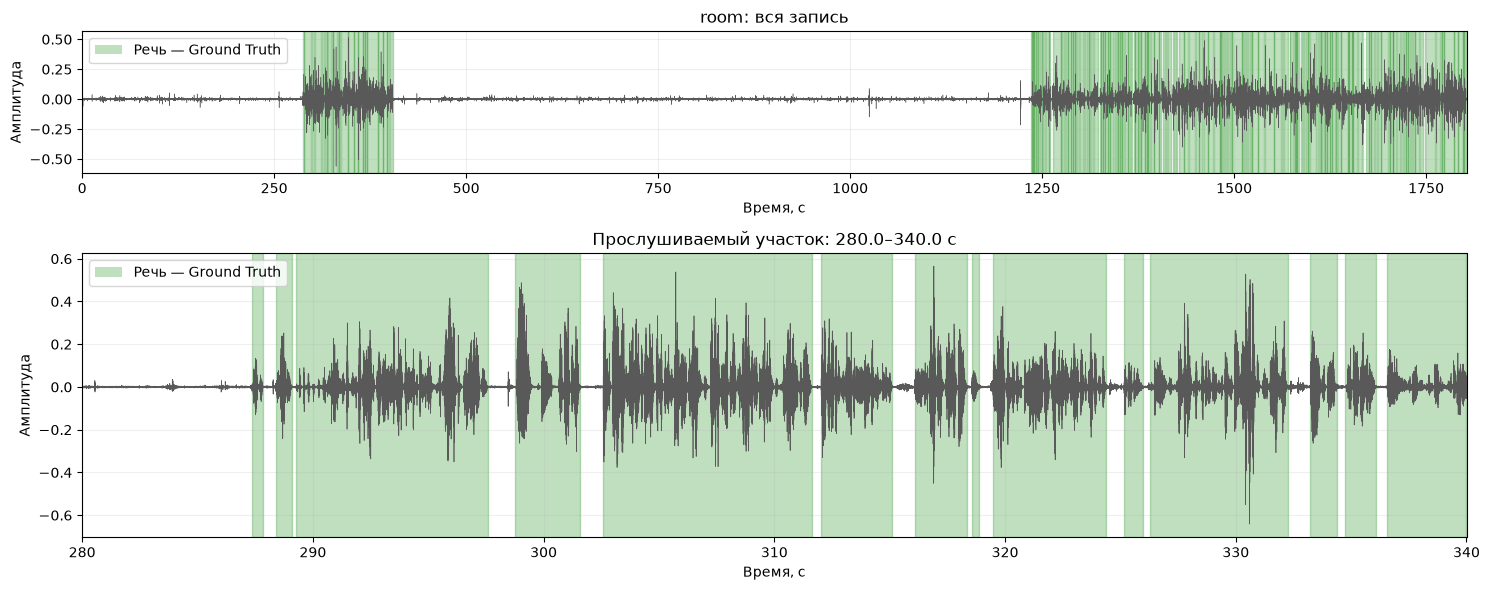

In [8]:
figure, axes = plt.subplots(2, 1, figsize=(15, 6), gridspec_kw={"height_ratios": [1, 2]})
overview_step = max(1, len(audio) // 80000)
axes[0].plot(
    np.arange(0, len(audio), overview_step) / sample_rate,
    audio[::overview_step].astype(np.float32) / audio_scale,
    color="0.35", linewidth=0.35,
)
for interval in speech_intervals.itertuples(index=False):
    axes[0].axvspan(interval.start, interval.end, color="green", alpha=0.25)
axes[0].set_xlim(0, duration)
axes[0].set_title(f"{recording_name}: вся запись")

preview_step = max(1, len(preview_audio) // 50000)
axes[1].plot(
    window_start + np.arange(0, len(preview_audio), preview_step) / sample_rate,
    preview_audio[::preview_step], color="0.35", linewidth=0.5,
)
visible_intervals = speech_intervals[
    (speech_intervals["start"] < window_end) & (speech_intervals["end"] > window_start)
]
for interval in visible_intervals.itertuples(index=False):
    axes[1].axvspan(
        max(interval.start, window_start), min(interval.end, window_end),
        color="green", alpha=0.25,
    )
axes[1].set_xlim(window_start, window_end)
axes[1].set_title(f"Прослушиваемый участок: {window_start:.1f}–{window_end:.1f} с")

for axis in axes:
    axis.set_xlabel("Время, с")
    axis.set_ylabel("Амплитуда")
    axis.grid(alpha=0.2)
    axis.legend(handles=[Patch(facecolor="green", alpha=0.25, label="Речь — Ground Truth")])
figure.tight_layout()
plt.show()